# EDA – Home Credit Default Risk

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sklearn.metrics import roc_auc_score

pd.set_option('display.max_columns', 200)
pd.set_option('display.max_rows', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

C0, C1 = '#2a78d6', '#eb6834'
INK, MUTED, GRID = '#0b0b0b', '#898781', '#e1e0d9'
SEQ = 'Blues'

plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e', 'axes.titlecolor': INK,
    'axes.titleweight': 'bold', 'axes.titlesize': 11, 'axes.grid': True,
    'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'legend.frameon': False, 'font.size': 9,
})

## 1. Wczytanie i przegląd danych

In [2]:
df = pd.read_csv('data/application_train.csv')
print(f'Kształt: {df.shape[0]:,} wierszy × {df.shape[1]} kolumn')
print(f'Pamięć: {df.memory_usage(deep=True).sum() / 1024**2:,.0f} MB')
df.head()

Kształt: 307,511 wierszy × 122 kolumn


Pamięć: 505 MB


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,"202,500.0000","406,597.5000","24,700.5000","351,000.0000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.0188,-9461,-637,"-3,648.0000",-2120,NaN,1,1,0,1,1,0,Laborers,1.0000,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.0830,0.2629,0.1394,0.0247,0.0369,0.9722,0.6192,0.0143,0.0000,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.0220,0.0198,0.0000,0.0000,0.0250,0.0369,0.9722,0.6243,0.0144,0.0000,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.0000,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0000,2.0000,2.0000,2.0000,"-1,134.0000",0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000
1,100003,0,Cash loans,F,N,N,0,"270,000.0000","1,293,502.5000","35,698.5000","1,129,500.0000",Family,State servant,Higher education,Married,House / apartment,0.0035,-16765,-1188,"-1,186.0000",-291,NaN,1,1,0,1,1,0,Core staff,2.0000,1,1,MONDAY,11,0,0,0,0,0,0,School,0.3113,0.6222,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.0800,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.0790,0.0554,0.0000,0.0000,0.0968,0.0529,0.9851,0.7987,0.0608,0.0800,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.0100,reg oper account,block of flats,0.0714,Block,No,1.0000,0.0000,1.0000,0.0000,-828.0000,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,100004,0,Revolving loans,M,Y,Y,0,"67,500.0000","135,000.0000","6,750.0000","135,000.0000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.0100,-19046,-225,"-4,260.0000",-2531,26.0000,1,1,1,1,1,0,Laborers,1.0000

In [3]:
print('Typy kolumn:')
print(df.dtypes.value_counts().to_string())
print()
print('Unikalne SK_ID_CURR:', df['SK_ID_CURR'].is_unique)
print('Zduplikowane wiersze (bez ID):', df.drop(columns='SK_ID_CURR').duplicated().sum())

Typy kolumn:
float64    65
int64      41
object     16

Unikalne SK_ID_CURR: True


Zduplikowane wiersze (bez ID): 0


In [4]:
nunique = df.nunique()
num_cols = df.select_dtypes(include='number').columns.drop(['SK_ID_CURR', 'TARGET'])
cat_cols = df.select_dtypes(include='object').columns.tolist()
bin_cols = [c for c in num_cols if nunique[c] == 2]
cont_cols = [c for c in num_cols if c not in bin_cols]
const_cols = nunique[nunique <= 1].index.tolist()

print(f'Numeryczne ciągłe/dyskretne: {len(cont_cols)}')
print(f'Numeryczne binarne (flagi): {len(bin_cols)}')
print(f'Kategoryczne (object): {len(cat_cols)}')
print(f'Stałe kolumny: {const_cols}')
print()
print('Kardynalność kolumn kategorycznych:')
print(nunique[cat_cols].sort_values(ascending=False).to_string())

Numeryczne ciągłe/dyskretne: 72
Numeryczne binarne (flagi): 32
Kategoryczne (object): 16
Stałe kolumny: []

Kardynalność kolumn kategorycznych:
ORGANIZATION_TYPE             58
OCCUPATION_TYPE               18
NAME_INCOME_TYPE               8
NAME_TYPE_SUITE                7
WALLSMATERIAL_MODE             7
WEEKDAY_APPR_PROCESS_START     7
NAME_FAMILY_STATUS             6
NAME_HOUSING_TYPE              6
NAME_EDUCATION_TYPE            5
FONDKAPREMONT_MODE             4
HOUSETYPE_MODE                 3
CODE_GENDER                    3
FLAG_OWN_CAR                   2
NAME_CONTRACT_TYPE             2
FLAG_OWN_REALTY                2
EMERGENCYSTATE_MODE            2


In [5]:
df[cont_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
CNT_CHILDREN,"307,511.0000",0.4171,0.7221,0.0000,0.0000,0.0000,1.0000,19.0000
AMT_INCOME_TOTAL,"307,511.0000","168,797.9193","237,123.1463","25,650.0000","112,500.0000","147,150.0000","202,500.0000","117,000,000.0000"
AMT_CREDIT,"307,511.0000","599,025.9997","402,490.7770","45,000.0000","270,000.0000","513,531.0000","808,650.0000","4,050,000.0000"
AMT_ANNUITY,"307,499.0000","27,108.5739","14,493.7373","1,615.5000","16,524.0000","24,903.0000","34,596.0000","258,025.5000"
AMT_GOODS_PRICE,"307,233.0000","538,396.2074","369,446.4605","40,500.0000","238,500.0000","450,000.0000","679,500.0000","4,050,000.0000"
REGION_POPULATION_RELATIVE,"307,511.0000",0.0209,0.0138,0.0003,0.0100,0.0188,0.0287,0.0725
DAYS_BIRTH,"307,511.0000","-16,036.9951","4,363.9886","-25,229.0000","-19,682.0000","-15,750.0000","-12,413.0000","-7,489.0000"
DAYS_EMPLOYED,"307,511.0000","63,815.0459","141,275.7665","-17,912.0000","-2,760.0000","-1,213.0000",-289.0000,"365,243.0000"
DAYS_REGISTRATION,"307,511.0000","-4,986.1203","3,522.8863","-24,672.0000","-7,479.5000","-4,504.0000","-2,010.0000",0.0000
DAYS_ID_PUBLISH,"307,511.0000","-2,994.2024","1,509.4504","-7,197.0000","-4,299.0000","-3,254.0000","-1,720.0000",0.0000


## 2. Zmienna celu `TARGET`

,liczba,udział
TARGET,,
0,282686,0.9193
1,24825,0.0807


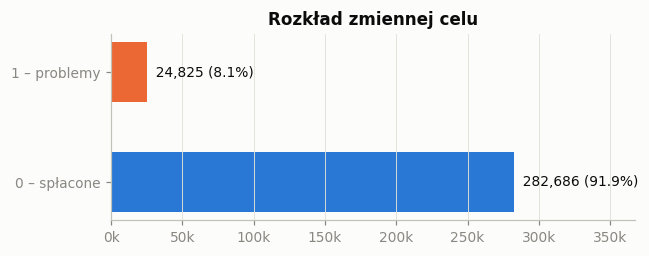

Bazowy default rate: 8.07%  |  stosunek klas ≈ 1:11.4


In [6]:
t = df['TARGET'].value_counts().sort_index()
share = t / t.sum()
display(pd.DataFrame({'liczba': t, 'udział': share}))

fig, ax = plt.subplots(figsize=(6, 2.4))
ax.barh(['0 – spłacone', '1 – problemy'], t.values, color=[C0, C1], height=0.55)
for i, (n, s) in enumerate(zip(t.values, share.values)):
    ax.text(n, i, f'  {n:,} ({s:.1%})', va='center', color=INK)
ax.set_xlim(0, t.max() * 1.3)
ax.set_title('Rozkład zmiennej celu')
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x/1000:.0f}k'))
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

BASE_RATE = df['TARGET'].mean()
print(f'Bazowy default rate: {BASE_RATE:.2%}  |  stosunek klas ≈ 1:{t[0]/t[1]:.1f}')

**Wniosek:** silnie niezbalansowany problem – accuracy jest bezużyteczną metryką (model „zawsze 0” ma ~92%).
Należy używać ROC AUC / PR AUC, stratyfikowanego podziału i ewentualnie wag klas.

## 3. Braki danych

Kolumny z brakami: 67 / 122


Kolumny z >50% braków: 41
Wiersze bez żadnego braku: 8,602


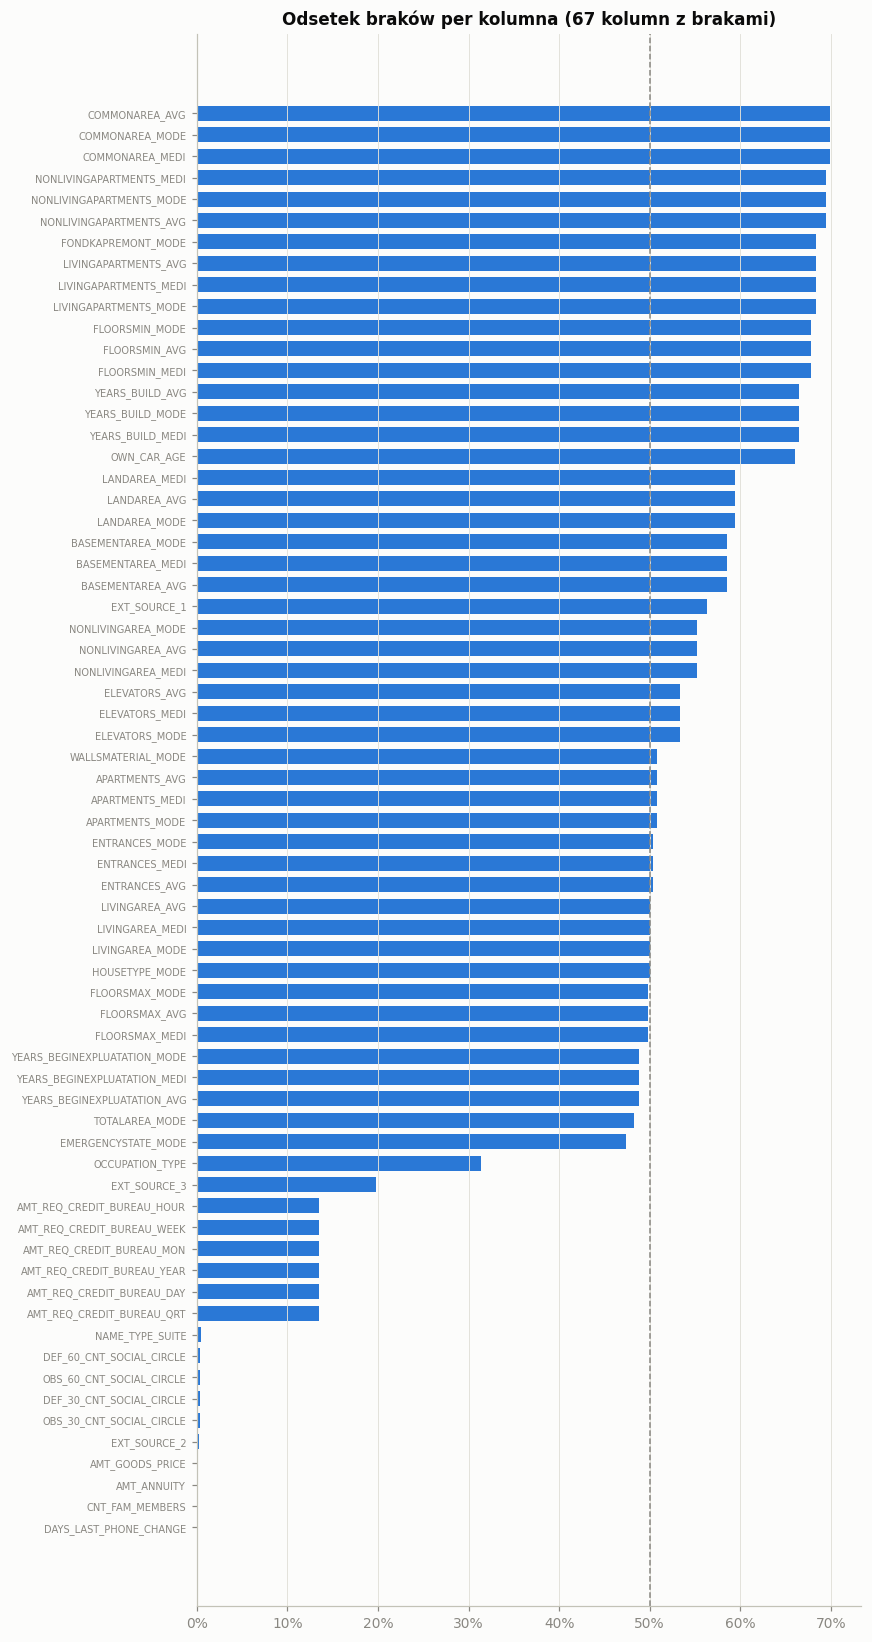

In [7]:
miss = df.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
print(f'Kolumny z brakami: {len(miss)} / {df.shape[1]}')
print(f'Kolumny z >50% braków: {(miss > 0.5).sum()}')
print(f'Wiersze bez żadnego braku: {df.notna().all(axis=1).sum():,}')

fig, ax = plt.subplots(figsize=(8, 15))
ax.barh(miss.index[::-1], miss.values[::-1], color=C0, height=0.7)
ax.axvline(0.5, color=MUTED, ls='--', lw=1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title(f'Odsetek braków per kolumna ({len(miss)} kolumn z brakami)')
ax.tick_params(axis='y', labelsize=6.5)
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

In [8]:
miss_groups = (miss.round(3).reset_index().rename(columns={'index': 'kolumna', 0: 'braki'})
               .groupby('braki')['kolumna'].agg(['count', lambda s: ', '.join(s[:4]) + (' …' if len(s) > 4 else '')])
               .rename(columns={'<lambda_0>': 'przykłady'}).sort_index(ascending=False))
miss_groups.head(25)

,count,przykłady
braki,,
0.6990,3,"COMMONAREA_AVG, COMMONAREA_MODE, COMMONAREA_MEDI"
0.6940,3,"NONLIVINGAPARTMENTS_MEDI, NONLIVINGAPARTMENTS_..."
0.6840,4,"FONDKAPREMONT_MODE, LIVINGAPARTMENTS_AVG, LIVI..."
0.6780,3,"FLOORSMIN_MODE, FLOORSMIN_AVG, FLOORSMIN_MEDI"
0.6650,3,"YEARS_BUILD_AVG, YEARS_BUILD_MODE, YEARS_BUILD..."
0.6600,1,OWN_CAR_AGE
0.5940,3,"LANDAREA_MEDI, LANDAREA_AVG, LANDAREA_MODE"
0.5850,3,"BASEMENTAREA_MODE, BASEMENTAREA_MEDI, BASEMENT..."
0.5640,1,EXT_SOURCE_1


In [9]:
rows = []
for c in miss.index:
    m = df[c].isna()
    if m.sum() < 1000 or (~m).sum() < 1000:
        continue
    rows.append({'kolumna': c, 'braki_%': m.mean(),
                 'DR_gdy_brak': df.loc[m, 'TARGET'].mean(),
                 'DR_gdy_jest': df.loc[~m, 'TARGET'].mean()})
miss_target = pd.DataFrame(rows)
miss_target['różnica_pp'] = (miss_target['DR_gdy_brak'] - miss_target['DR_gdy_jest']) * 100
miss_target.sort_values('różnica_pp', key=abs, ascending=False).head(15)

,kolumna,braki_%,DR_gdy_brak,DR_gdy_jest,różnica_pp
60,DEF_30_CNT_SOCIAL_CIRCLE,0.0033,0.0353,0.0809,-4.5621
61,OBS_30_CNT_SOCIAL_CIRCLE,0.0033,0.0353,0.0809,-4.5621
58,DEF_60_CNT_SOCIAL_CIRCLE,0.0033,0.0353,0.0809,-4.5621
59,OBS_60_CNT_SOCIAL_CIRCLE,0.0033,0.0353,0.0809,-4.5621
57,NAME_TYPE_SUITE,0.0042,0.0542,0.0808,-2.6661
53,AMT_REQ_CREDIT_BUREAU_MON,0.1350,0.1034,0.0772,2.6180
51,AMT_REQ_CREDIT_BUREAU_HOUR,0.1350,0.1034,0.0772,2.6180
52,AMT_REQ_CREDIT_BUREAU_WEEK,0.1350,0.1034,0.0772,2.6180
55,AMT_REQ_CREDIT_BUREAU_DAY,0.1350,0.1034,0.0772,2.6180
56,AMT_REQ_CREDIT_BUREAU_QRT,0.1350,0.1034,0.0772,2.6180


Grupa ~47 kolumn opisujących budynek (`*_AVG`, `*_MODE`, `*_MEDI`) ma 48–70% braków – to jeden blok danych
wypełniany razem. Braki **nie są losowe** (MNAR): brak informacji o mieszkaniu / `EXT_SOURCE_*` / `OCCUPATION_TYPE`
wiąże się z wyższym default rate, więc warto dodać flagi `is_missing` lub zostawić NaN dla modeli drzewiastych.

## 4. Anomalie i błędy w danych

In [10]:
anom = df['DAYS_EMPLOYED'] == 365243
print(f'DAYS_EMPLOYED == 365243: {anom.sum():,} wierszy ({anom.mean():.1%})')
print('Typ dochodu dla anomalii:')
print(df.loc[anom, 'NAME_INCOME_TYPE'].value_counts().to_string())
print(f'\nDefault rate – anomalie: {df.loc[anom, "TARGET"].mean():.2%}  vs reszta: {df.loc[~anom, "TARGET"].mean():.2%}')

DAYS_EMPLOYED == 365243: 55,374 wierszy (18.0%)
Typ dochodu dla anomalii:
NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22

Default rate – anomalie: 5.40%  vs reszta: 8.66%


In [11]:
print('CODE_GENDER:', df['CODE_GENDER'].value_counts().to_dict())
print('NAME_FAMILY_STATUS Unknown:', (df['NAME_FAMILY_STATUS'] == 'Unknown').sum())
print('ORGANIZATION_TYPE XNA:', (df['ORGANIZATION_TYPE'] == 'XNA').sum(), '(pokrywa się z emerytami/bezrobotnymi)')
print()
print('Max AMT_INCOME_TOTAL:', f"{df['AMT_INCOME_TOTAL'].max():,.0f}",
      '| 99.9 percentyl:', f"{df['AMT_INCOME_TOTAL'].quantile(0.999):,.0f}")
print('Max CNT_CHILDREN:', df['CNT_CHILDREN'].max(), '| Max CNT_FAM_MEMBERS:', df['CNT_FAM_MEMBERS'].max())
print('Max OBS_30_CNT_SOCIAL_CIRCLE:', df['OBS_30_CNT_SOCIAL_CIRCLE'].max(),
      '| 99.9 percentyl:', df['OBS_30_CNT_SOCIAL_CIRCLE'].quantile(0.999))
print('Max AMT_REQ_CREDIT_BUREAU_QRT:', df['AMT_REQ_CREDIT_BUREAU_QRT'].max())
print('DAYS_LAST_PHONE_CHANGE == 0:', (df['DAYS_LAST_PHONE_CHANGE'] == 0).sum())
print('AMT_GOODS_PRICE > AMT_CREDIT:', (df['AMT_GOODS_PRICE'] > df['AMT_CREDIT']).sum())

CODE_GENDER: {'F': 202448, 'M': 105059, 'XNA': 4}
NAME_FAMILY_STATUS Unknown: 2
ORGANIZATION_TYPE XNA: 55374 (pokrywa się z emerytami/bezrobotnymi)

Max AMT_INCOME_TOTAL: 117,000,000 | 99.9 percentyl: 900,000
Max CNT_CHILDREN: 19 | Max CNT_FAM_MEMBERS: 20.0
Max OBS_30_CNT_SOCIAL_CIRCLE: 348.0 | 99.9 percentyl: 17.0
Max AMT_REQ_CREDIT_BUREAU_QRT: 261.0
DAYS_LAST_PHONE_CHANGE == 0: 37672
AMT_GOODS_PRICE > AMT_CREDIT: 260


In [12]:
days_cols = [c for c in df.columns if c.startswith('DAYS_')]
pd.DataFrame({'min': df[days_cols].min(), 'max': df[days_cols].max(),
              'liczba > 0': (df[days_cols] > 0).sum()})

,min,max,liczba > 0
DAYS_BIRTH,"-25,229.0000","-7,489.0000",0
DAYS_EMPLOYED,"-17,912.0000","365,243.0000",55374
DAYS_REGISTRATION,"-24,672.0000",0.0000,0
DAYS_ID_PUBLISH,"-7,197.0000",0.0000,0
DAYS_LAST_PHONE_CHANGE,"-4,292.0000",0.0000,0


In [13]:
# 4d. Kolumny prawie stałe (dominująca wartość > 99%)
dom = df.apply(lambda s: s.value_counts(normalize=True, dropna=False).iloc[0])
near_const = dom[dom > 0.99].sort_values(ascending=False)
near_const.to_frame('udział_dominującej')

,udział_dominującej
FLAG_MOBIL,1.0000
FLAG_DOCUMENT_12,1.0000
FLAG_DOCUMENT_10,1.0000
FLAG_DOCUMENT_2,1.0000
FLAG_DOCUMENT_4,0.9999
FLAG_DOCUMENT_7,0.9998
FLAG_DOCUMENT_17,0.9997
FLAG_DOCUMENT_21,0.9997
FLAG_DOCUMENT_20,0.9995
FLAG_DOCUMENT_19,0.9994


In [14]:
d = df.copy()
d['DAYS_EMPLOYED_ANOM'] = (d['DAYS_EMPLOYED'] == 365243).astype(int)
d['DAYS_EMPLOYED'] = d['DAYS_EMPLOYED'].replace(365243, np.nan)
d.loc[d['CODE_GENDER'] == 'XNA', 'CODE_GENDER'] = np.nan
d['AGE_YEARS'] = -d['DAYS_BIRTH'] / 365.25
d['EMPLOYED_YEARS'] = -d['DAYS_EMPLOYED'] / 365.25
print(d[['AGE_YEARS', 'EMPLOYED_YEARS']].describe().T)

                      count    mean     std     min     25%     50%     75%  \
AGE_YEARS      307,511.0000 43.9069 11.9479 20.5038 33.9849 43.1211 53.8864   
EMPLOYED_YEARS 252,137.0000  6.5275  6.4021 -0.0000  2.0999  4.5120  8.6927   

                   max  
AGE_YEARS      69.0732  
EMPLOYED_YEARS 49.0404  


## 5. Zmienne numeryczne

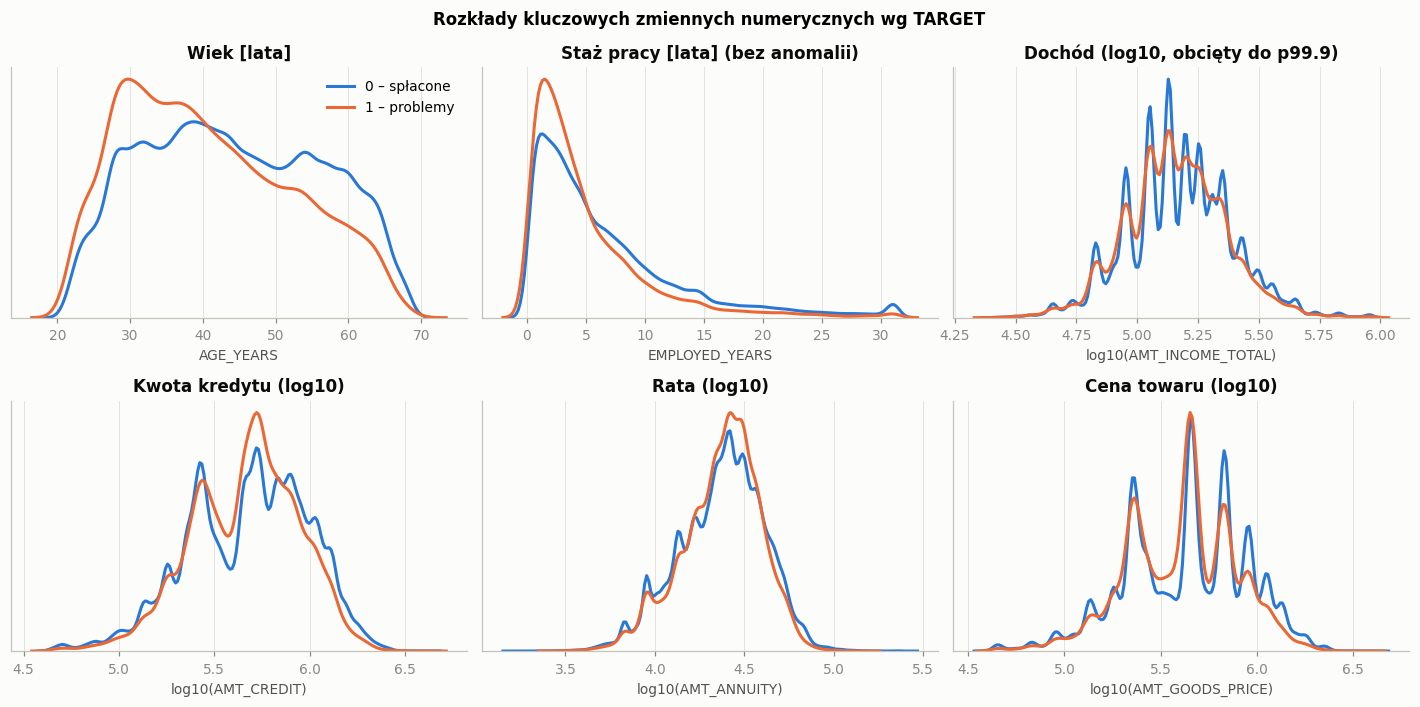

In [15]:
def kde_by_target(ax, col, data=d, log=False, clip_q=None, title=None):
    s = data[[col, 'TARGET']].dropna()
    x = s[col]
    if clip_q:
        x = x.clip(upper=x.quantile(clip_q))
    if log:
        x = np.log10(x.clip(lower=1))
    for tval, color, label in [(0, C0, '0 – spłacone'), (1, C1, '1 – problemy')]:
        sns.kdeplot(x[s['TARGET'] == tval], ax=ax, color=color, lw=2, label=label, common_norm=False)
    ax.set_title(title or col)
    ax.set_xlabel('log10(' + col + ')' if log else col)
    ax.set_ylabel('')
    ax.set_yticks([])

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
kde_by_target(axes[0, 0], 'AGE_YEARS', title='Wiek [lata]')
kde_by_target(axes[0, 1], 'EMPLOYED_YEARS', clip_q=0.99, title='Staż pracy [lata] (bez anomalii)')
kde_by_target(axes[0, 2], 'AMT_INCOME_TOTAL', log=True, clip_q=0.999, title='Dochód (log10, obcięty do p99.9)')
kde_by_target(axes[1, 0], 'AMT_CREDIT', log=True, title='Kwota kredytu (log10)')
kde_by_target(axes[1, 1], 'AMT_ANNUITY', log=True, title='Rata (log10)')
kde_by_target(axes[1, 2], 'AMT_GOODS_PRICE', log=True, title='Cena towaru (log10)')
axes[0, 0].legend()
fig.suptitle('Rozkłady kluczowych zmiennych numerycznych wg TARGET', fontweight='bold')
plt.tight_layout(); plt.show()

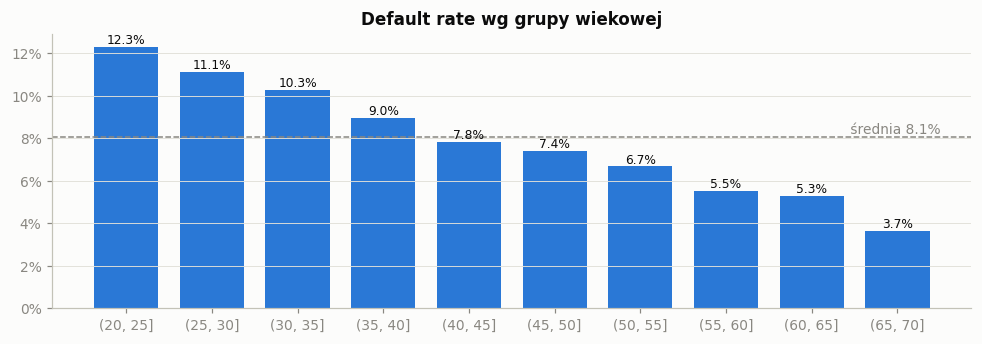

In [16]:
d['AGE_BIN'] = pd.cut(d['AGE_YEARS'], bins=range(20, 75, 5))
age_dr = d.groupby('AGE_BIN', observed=True)['TARGET'].agg(['mean', 'size'])

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(age_dr.index.astype(str), age_dr['mean'], color=C0, width=0.75)
ax.axhline(BASE_RATE, color=MUTED, ls='--', lw=1)
ax.text(len(age_dr) - 0.5, BASE_RATE, f' średnia {BASE_RATE:.1%}', color=MUTED, va='bottom', ha='right')
for i, v in enumerate(age_dr['mean']):
    ax.text(i, v, f'{v:.1%}', ha='center', va='bottom', fontsize=8, color=INK)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_title('Default rate wg grupy wiekowej'); ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

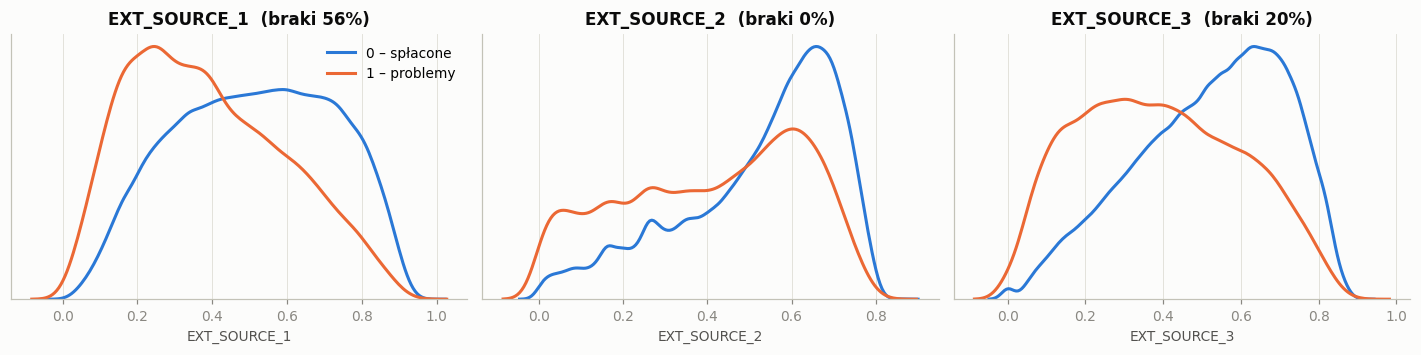

,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,AGE_YEARS,TARGET
EXT_SOURCE_1,1.0000,0.2140,0.1868,0.6006,-0.1553
EXT_SOURCE_2,0.2140,1.0000,0.1092,0.0920,-0.1605
EXT_SOURCE_3,0.1868,0.1092,1.0000,0.2055,-0.1789
AGE_YEARS,0.6006,0.0920,0.2055,1.0000,-0.0782
TARGET,-0.1553,-0.1605,-0.1789,-0.0782,1.0000


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
for ax, c in zip(axes, ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']):
    kde_by_target(ax, c, title=f'{c}  (braki {df[c].isna().mean():.0%})')
axes[0].legend()
plt.tight_layout(); plt.show()

ext = d[['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'AGE_YEARS', 'TARGET']].corr()
ext

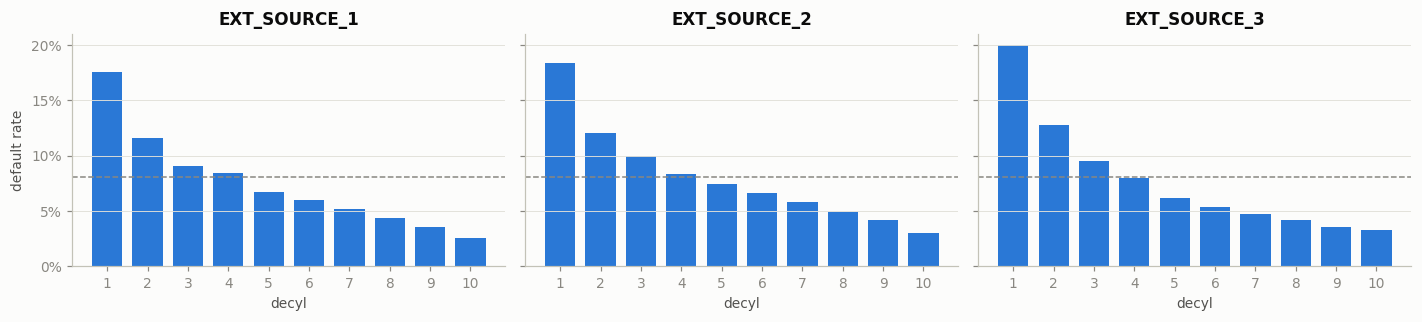

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3), sharey=True)
for ax, c in zip(axes, ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']):
    g = d.groupby(pd.qcut(d[c], 10, labels=False, duplicates='drop'))['TARGET'].mean()
    ax.bar(g.index + 1, g.values, color=C0, width=0.75)
    ax.axhline(BASE_RATE, color=MUTED, ls='--', lw=1)
    ax.set_title(c); ax.set_xlabel('decyl'); ax.set_xticks(range(1, 11))
    ax.grid(axis='x', visible=False)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
axes[0].set_ylabel('default rate')
plt.tight_layout(); plt.show()

In [19]:
skew = d[cont_cols].skew().sort_values(ascending=False)
print('Najbardziej skośne zmienne (|skew| > 5):')
print(skew[skew.abs() > 5].round(1).to_string())

Najbardziej skośne zmienne (|skew| > 5):
AMT_INCOME_TOTAL               391.6000
AMT_REQ_CREDIT_BUREAU_QRT      134.4000
AMT_REQ_CREDIT_BUREAU_DAY       27.0000
NONLIVINGAPARTMENTS_MODE        16.3000
NONLIVINGAPARTMENTS_MEDI        15.7000
NONLIVINGAPARTMENTS_AVG         15.5000
AMT_REQ_CREDIT_BUREAU_HOUR      14.5000
OBS_30_CNT_SOCIAL_CIRCLE        12.1000
OBS_60_CNT_SOCIAL_CIRCLE        12.1000
AMT_REQ_CREDIT_BUREAU_WEEK       9.3000
AMT_REQ_CREDIT_BUREAU_MON        7.8000
NONLIVINGAREA_AVG                6.6000
NONLIVINGAREA_MODE               6.5000
NONLIVINGAREA_MEDI               6.5000
COMMONAREA_MODE                  5.6000
COMMONAREA_AVG                   5.5000
COMMONAREA_MEDI                  5.4000
DEF_60_CNT_SOCIAL_CIRCLE         5.3000
DEF_30_CNT_SOCIAL_CIRCLE         5.2000
YEARS_BEGINEXPLUATATION_MODE   -14.8000
YEARS_BEGINEXPLUATATION_AVG    -15.5000
YEARS_BEGINEXPLUATATION_MEDI   -15.6000


## 6. Zmienne kategoryczne

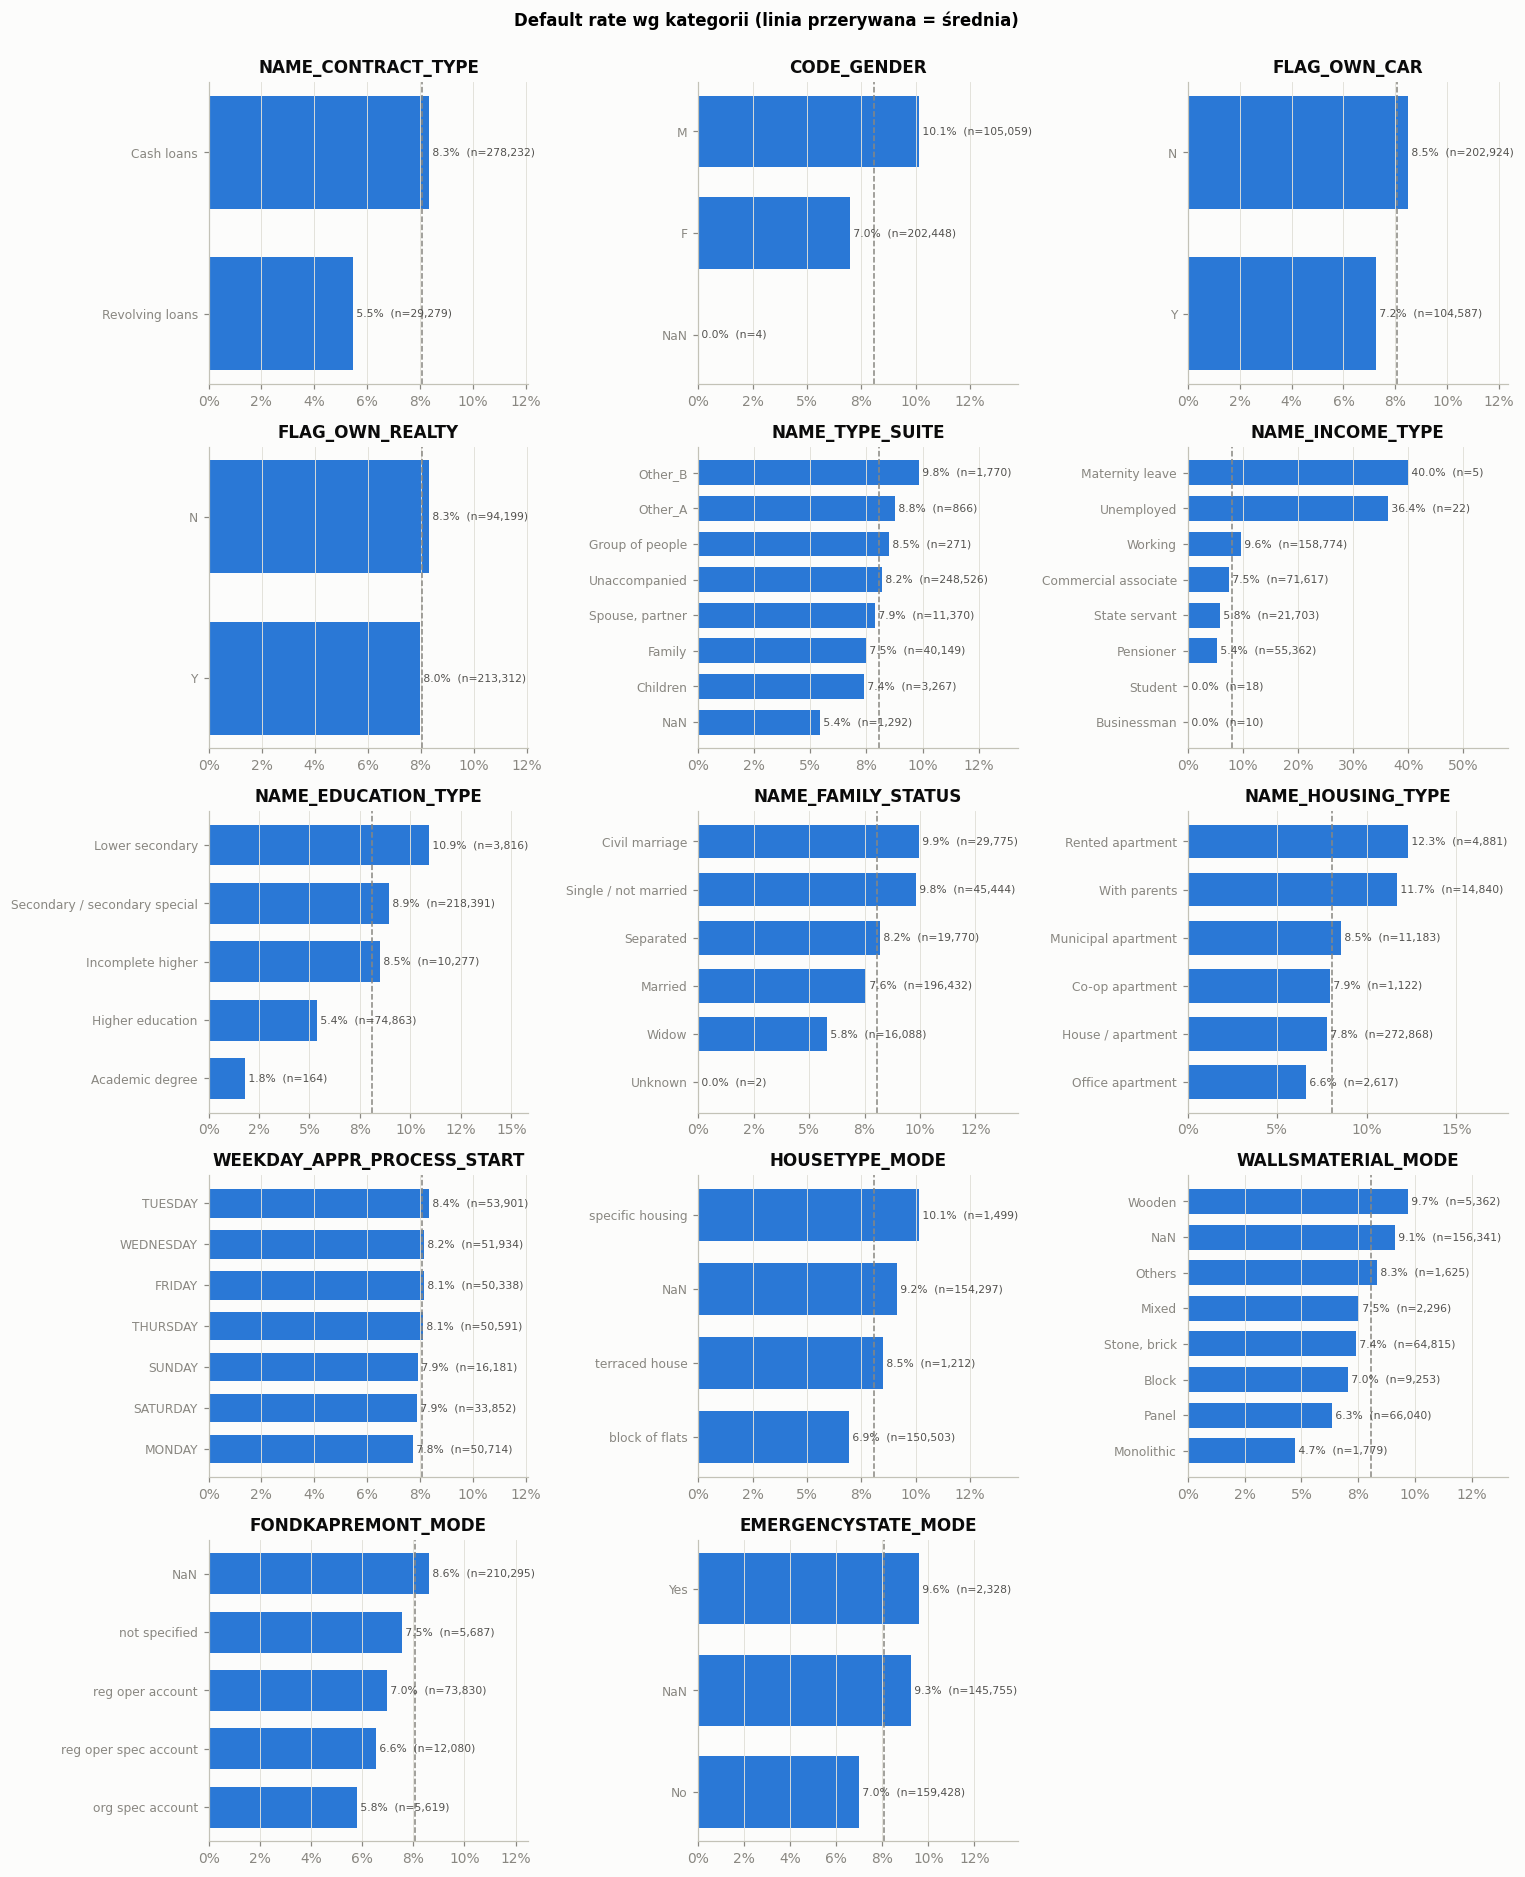

In [20]:
def cat_dr(col, data=d, top=None, ax=None, min_n=0):
    g = data.groupby(col, dropna=False)['TARGET'].agg(['mean', 'size'])
    g.index = g.index.fillna('NaN') if hasattr(g.index, 'fillna') else g.index
    g = g[g['size'] >= min_n].sort_values('mean')
    if top:
        g = g.tail(top)
    ax.barh(g.index.astype(str), g['mean'], color=C0, height=0.7)
    ax.axvline(BASE_RATE, color=MUTED, ls='--', lw=1)
    for i, (v, n) in enumerate(zip(g['mean'], g['size'])):
        ax.text(v, i, f' {v:.1%}  (n={n:,})', va='center', fontsize=7, color='#52514e')
    ax.set_xlim(0, g['mean'].max() * 1.45)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
    ax.set_title(col); ax.grid(axis='y', visible=False)
    ax.tick_params(axis='y', labelsize=8)
    return g

small_cats = ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY',
              'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS',
              'NAME_HOUSING_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE',
              'FONDKAPREMONT_MODE', 'EMERGENCYSTATE_MODE']
fig, axes = plt.subplots(5, 3, figsize=(14, 17))
for ax, c in zip(axes.flat, small_cats):
    cat_dr(c, ax=ax)
for ax in axes.flat[len(small_cats):]:
    ax.axis('off')
fig.suptitle('Default rate wg kategorii (linia przerywana = średnia)', fontweight='bold', y=1.0)
plt.tight_layout(); plt.show()

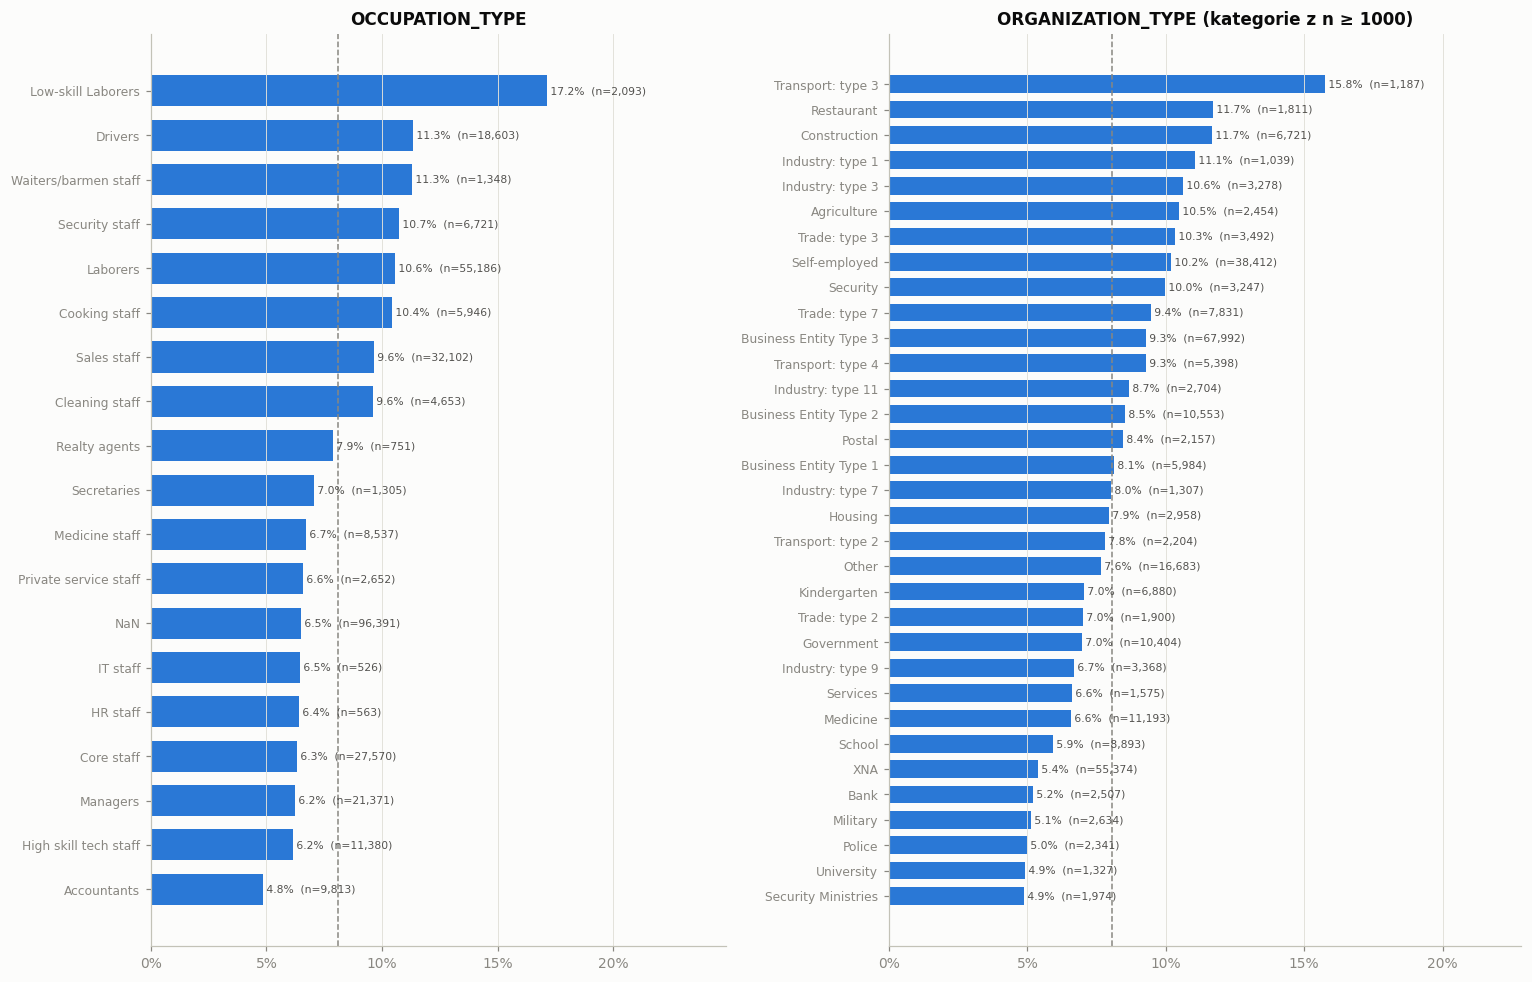

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 9), gridspec_kw={'width_ratios': [1, 1.1]})
cat_dr('OCCUPATION_TYPE', ax=axes[0])
cat_dr('ORGANIZATION_TYPE', ax=axes[1], min_n=1000)
axes[1].set_title('ORGANIZATION_TYPE (kategorie z n ≥ 1000)')
plt.tight_layout(); plt.show()

In [22]:
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    ct = pd.crosstab(x.fillna('NaN'), y)
    chi2 = chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum()
    r, k = ct.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

cv = pd.Series({c: cramers_v(d[c], d['TARGET']) for c in cat_cols}).sort_values(ascending=False)
cv.to_frame("Cramér's V")

,Cramér's V
OCCUPATION_TYPE,0.0801
ORGANIZATION_TYPE,0.0723
NAME_INCOME_TYPE,0.0638
NAME_EDUCATION_TYPE,0.0576
CODE_GENDER,0.0547
WALLSMATERIAL_MODE,0.0441
EMERGENCYSTATE_MODE,0.0422
HOUSETYPE_MODE,0.0407
NAME_FAMILY_STATUS,0.0405
NAME_HOUSING_TYPE,0.0370


## 7. Flagi binarne

In [23]:
rows = []
for c in bin_cols:
    vc = d[c].value_counts()
    rows.append({'flaga': c, 'udział_1': (d[c] == 1).mean(),
                 'DR_gdy_1': d.loc[d[c] == 1, 'TARGET'].mean(),
                 'DR_gdy_0': d.loc[d[c] == 0, 'TARGET'].mean()})
flags = pd.DataFrame(rows)
flags['różnica_pp'] = (flags['DR_gdy_1'] - flags['DR_gdy_0']) * 100
flags.sort_values('różnica_pp', key=abs, ascending=False)

,flaga,udział_1,DR_gdy_1,DR_gdy_0,różnica_pp
12,FLAG_DOCUMENT_2,0.0000,0.3077,0.0807,22.6973
14,FLAG_DOCUMENT_4,0.0001,0.0000,0.0807,-8.0735
20,FLAG_DOCUMENT_10,0.0000,0.0000,0.0807,-8.0731
22,FLAG_DOCUMENT_12,0.0000,0.0000,0.0807,-8.0729
0,FLAG_MOBIL,1.0000,0.0807,0.0000,8.0729
27,FLAG_DOCUMENT_17,0.0003,0.0244,0.0807,-5.6354
31,FLAG_DOCUMENT_21,0.0003,0.1359,0.0807,5.5212
23,FLAG_DOCUMENT_13,0.0035,0.0277,0.0809,-5.3241
25,FLAG_DOCUMENT_15,0.0012,0.0296,0.0808,-5.1221
24,FLAG_DOCUMENT_14,0.0029,0.0332,0.0809,-4.7646


## 8. Korelacje i siła predykcyjna

In [24]:
num_all = [c for c in d.select_dtypes(include='number').columns
           if c not in ('SK_ID_CURR', 'TARGET', 'AGE_YEARS', 'EMPLOYED_YEARS')]
pearson = d[num_all].corrwith(d['TARGET'])
spearman = d[num_all].corrwith(d['TARGET'], method='spearman')

def uni_auc(col):
    s = d[[col, 'TARGET']].dropna()
    if s[col].nunique() < 2:
        return np.nan
    a = roc_auc_score(s['TARGET'], s[col])
    return max(a, 1 - a)

auc = pd.Series({c: uni_auc(c) for c in num_all})
corr_tbl = pd.DataFrame({'pearson': pearson, 'spearman': spearman, 'AUC_jednowym.': auc,
                         'braki_%': d[num_all].isna().mean()})
top = corr_tbl.reindex(corr_tbl['AUC_jednowym.'].sort_values(ascending=False).index)
top.head(25)

,pearson,spearman,AUC_jednowym.,braki_%
EXT_SOURCE_3,-0.1789,-0.1663,0.6794,0.1983
EXT_SOURCE_1,-0.1553,-0.1511,0.6657,0.5638
EXT_SOURCE_2,-0.1605,-0.1473,0.6561,0.0021
DAYS_BIRTH,0.0782,0.0783,0.5830,0.0000
DAYS_EMPLOYED,0.0750,0.0803,0.5824,0.1801
OWN_CAR_AGE,0.0376,0.0529,0.5589,0.6599
DAYS_LAST_PHONE_CHANGE,0.0552,0.0537,0.5569,0.0000
DAYS_ID_PUBLISH,0.0515,0.0525,0.5557,0.0000
FLOORSMAX_AVG,-0.0440,-0.0462,0.5504,0.4976
FLOORSMAX_MEDI,-0.0438,-0.0460,0.5500,0.4976


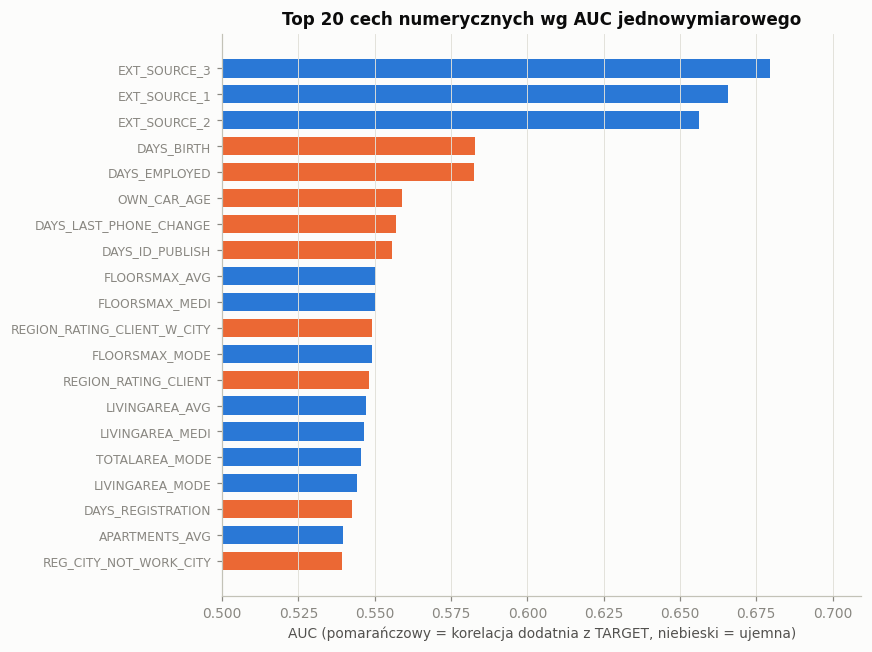

In [25]:
t20 = top.head(20)
fig, ax = plt.subplots(figsize=(8, 6))
colors = [C1 if v > 0 else C0 for v in t20['spearman']]
ax.barh(t20.index[::-1], t20['AUC_jednowym.'][::-1] - 0.5, left=0.5, color=colors[::-1], height=0.7)
ax.set_xlim(0.5, t20['AUC_jednowym.'].max() + 0.03)
ax.set_title('Top 20 cech numerycznych wg AUC jednowymiarowego')
ax.set_xlabel('AUC (pomarańczowy = korelacja dodatnia z TARGET, niebieski = ujemna)')
ax.grid(axis='y', visible=False); ax.tick_params(axis='y', labelsize=8)
plt.tight_layout(); plt.show()

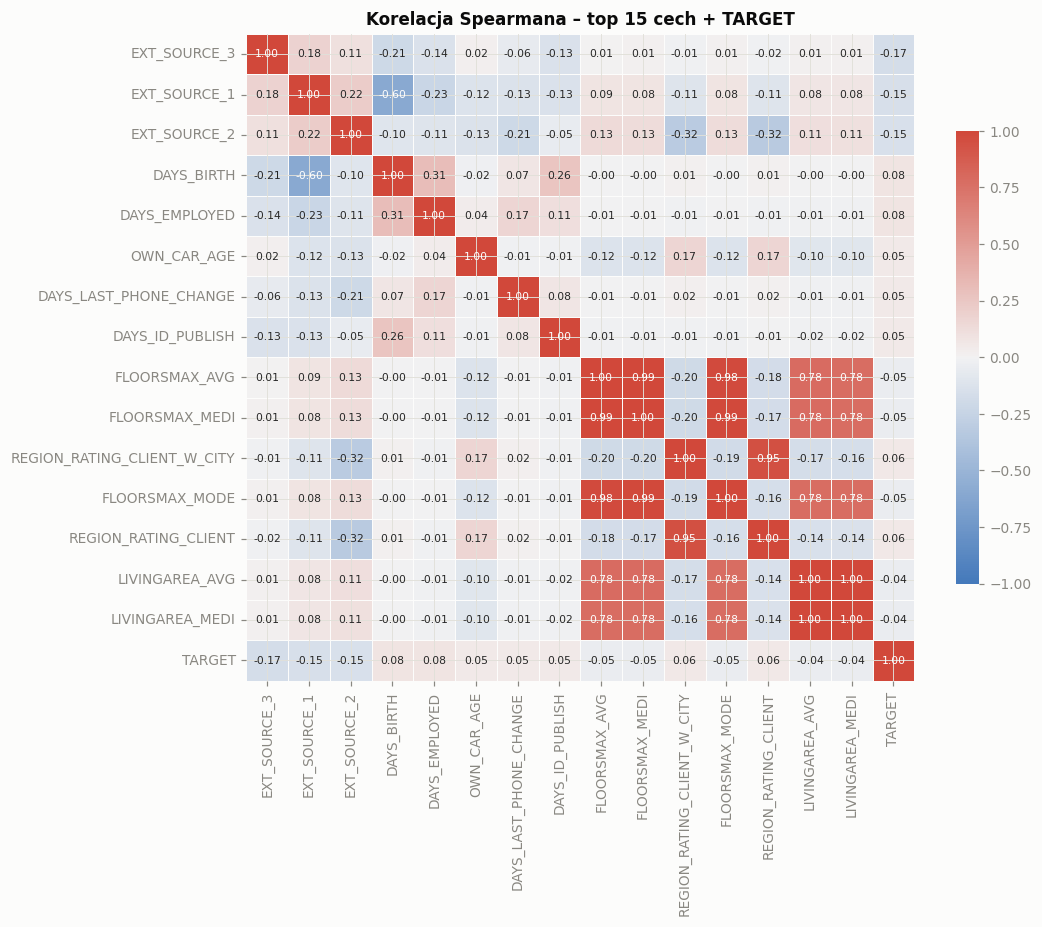

In [26]:
top_feats = top.head(15).index.tolist()
cm = d[top_feats + ['TARGET']].corr(method='spearman')
fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(cm, cmap=sns.diverging_palette(250, 15, s=75, l=50, as_cmap=True), center=0, vmin=-1, vmax=1,
            annot=True, fmt='.2f', annot_kws={'size': 7}, linewidths=0.5, linecolor='#fcfcfb', ax=ax,
            cbar_kws={'shrink': 0.7})
ax.set_title('Korelacja Spearmana – top 15 cech + TARGET')
plt.tight_layout(); plt.show()

In [27]:
c = d[num_all].corr().abs()
upper = c.where(np.triu(np.ones(c.shape, dtype=bool), k=1))
pairs = upper.stack().loc[lambda s: s > 0.95].sort_values(ascending=False)
print(f'Liczba par |r| > 0.95: {len(pairs)}')
print(f'Liczba zmiennych zaangażowanych: {len(set(pairs.index.get_level_values(0)) | set(pairs.index.get_level_values(1)))}')
pairs.head(25).to_frame('|r|')

Liczba par |r| > 0.95: 46
Liczba zmiennych zaangażowanych: 50


,,|r|
FLAG_EMP_PHONE,DAYS_EMPLOYED_ANOM,0.9999
YEARS_BUILD_AVG,YEARS_BUILD_MEDI,0.9985
OBS_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,0.9985
FLOORSMIN_AVG,FLOORSMIN_MEDI,0.9972
FLOORSMAX_AVG,FLOORSMAX_MEDI,0.9970
ENTRANCES_AVG,ENTRANCES_MEDI,0.9969
ELEVATORS_AVG,ELEVATORS_MEDI,0.9961
COMMONAREA_AVG,COMMONAREA_MEDI,0.9960
LIVINGAREA_AVG,LIVINGAREA_MEDI,0.9956
APARTMENTS_AVG,APARTMENTS_MEDI,0.9951


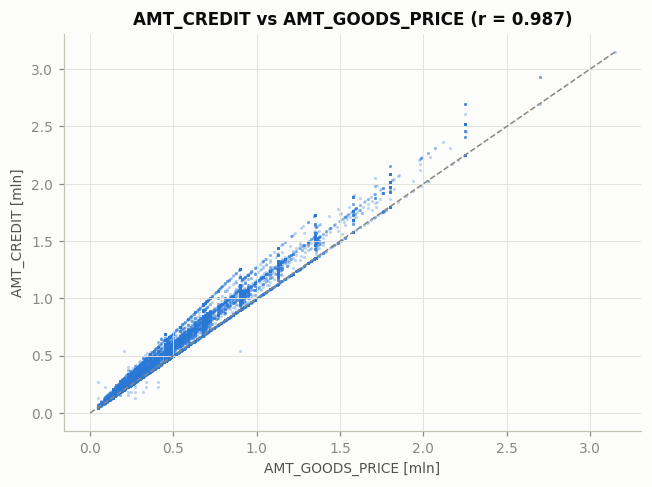

In [28]:
fig, ax = plt.subplots(figsize=(6, 4.5))
s = d[['AMT_CREDIT', 'AMT_GOODS_PRICE']].dropna().sample(20000, random_state=0)
ax.scatter(s['AMT_GOODS_PRICE'] / 1e6, s['AMT_CREDIT'] / 1e6, s=4, alpha=0.3, color=C0, linewidths=0)
lim = s.max().max() / 1e6
ax.plot([0, lim], [0, lim], color=MUTED, ls='--', lw=1)
ax.set_xlabel('AMT_GOODS_PRICE [mln]'); ax.set_ylabel('AMT_CREDIT [mln]')
ax.set_title(f"AMT_CREDIT vs AMT_GOODS_PRICE (r = {d['AMT_CREDIT'].corr(d['AMT_GOODS_PRICE']):.3f})")
plt.tight_layout(); plt.show()

## 9. Cechy pochodne (ratio)

In [29]:
d['CREDIT_INCOME_RATIO'] = d['AMT_CREDIT'] / d['AMT_INCOME_TOTAL']
d['ANNUITY_INCOME_RATIO'] = d['AMT_ANNUITY'] / d['AMT_INCOME_TOTAL']
d['CREDIT_TERM'] = d['AMT_CREDIT'] / d['AMT_ANNUITY']
d['GOODS_CREDIT_RATIO'] = d['AMT_GOODS_PRICE'] / d['AMT_CREDIT']
d['EMPLOYED_AGE_RATIO'] = d['EMPLOYED_YEARS'] / d['AGE_YEARS']
d['EXT_SOURCE_MEAN'] = d[['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']].mean(axis=1)
d['INCOME_PER_PERSON'] = d['AMT_INCOME_TOTAL'] / d['CNT_FAM_MEMBERS']

new_feats = ['CREDIT_INCOME_RATIO', 'ANNUITY_INCOME_RATIO', 'CREDIT_TERM', 'GOODS_CREDIT_RATIO',
             'EMPLOYED_AGE_RATIO', 'EXT_SOURCE_MEAN', 'INCOME_PER_PERSON']
pd.DataFrame({'AUC_jednowym.': {f: uni_auc(f) for f in new_feats},
              'spearman': d[new_feats].corrwith(d['TARGET'], method='spearman')}).sort_values('AUC_jednowym.', ascending=False)

,AUC_jednowym.,spearman
EXT_SOURCE_MEAN,0.7165,-0.2043
EMPLOYED_AGE_RATIO,0.5697,-0.0679
GOODS_CREDIT_RATIO,0.5692,-0.0668
CREDIT_TERM,0.5321,-0.0303
ANNUITY_INCOME_RATIO,0.5195,0.0184
INCOME_PER_PERSON,0.5176,-0.0166
CREDIT_INCOME_RATIO,0.5019,-0.0018


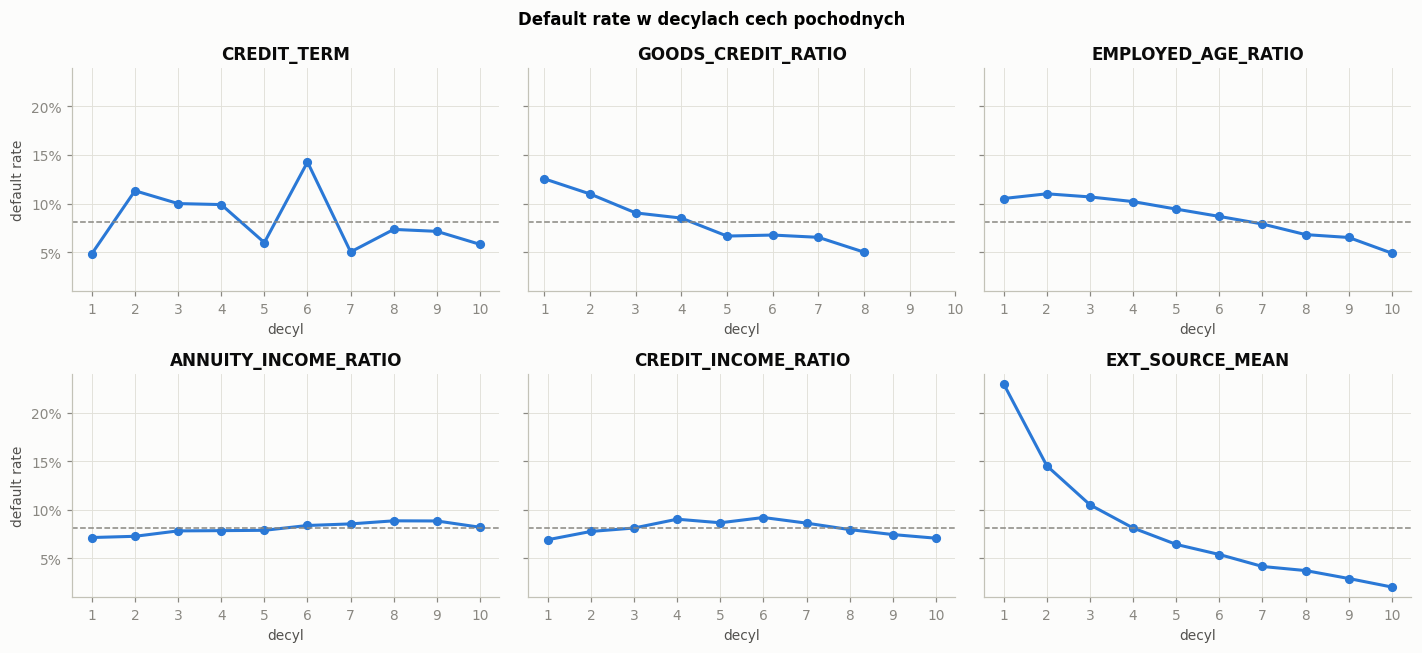

In [30]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharey=True)
for ax, f in zip(axes.flat, ['CREDIT_TERM', 'GOODS_CREDIT_RATIO', 'EMPLOYED_AGE_RATIO',
                             'ANNUITY_INCOME_RATIO', 'CREDIT_INCOME_RATIO', 'EXT_SOURCE_MEAN']):
    g = d.groupby(pd.qcut(d[f], 10, labels=False, duplicates='drop'))['TARGET'].mean()
    ax.plot(g.index + 1, g.values, color=C0, lw=2, marker='o', ms=5)
    ax.axhline(BASE_RATE, color=MUTED, ls='--', lw=1)
    ax.set_title(f); ax.set_xticks(range(1, 11)); ax.set_xlabel('decyl')
for ax in axes[:, 0]:
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.set_ylabel('default rate')
fig.suptitle('Default rate w decylach cech pochodnych', fontweight='bold')
plt.tight_layout(); plt.show()

## 10. Podsumowanie i rekomendacje

### Najważniejsze obserwacje

**Zmienna celu**
- 307 511 wniosków, default rate **8,07%** (≈ 1:11,4) → silna nierównowaga klas. Metryka: ROC AUC / PR AUC, podział stratyfikowany.

**Jakość danych**
- 67 ze 122 kolumn ma braki, 41 z nich ponad 50%; tylko 8 602 wiersze są kompletne.
- ~47 kolumn o budynku (`*_AVG/_MODE/_MEDI`, 48–70% braków) tworzy jeden blok – brakuje ich razem. `EXT_SOURCE_1` ma 56% braków, `OCCUPATION_TYPE` 31%, `EXT_SOURCE_3` 20%.
- Braki **nie są losowe**: brak danych o budynku → DR ~9,2% vs 7,0%; brak `AMT_REQ_CREDIT_BUREAU_*` → 10,3% vs 7,7%.
- `DAYS_EMPLOYED = 365243` w 55 374 wierszach (18%) – to niemal wyłącznie emeryci (placeholder „brak zatrudnienia”). Ta grupa ma **niższy** DR (5,4% vs 8,7%), więc flagę anomalii warto zachować jako cechę.
- Drobne błędy: `CODE_GENDER = XNA` (4), `NAME_FAMILY_STATUS = Unknown` (2), dochód 117 mln (p99,9 = 900 tys.), `OBS_30_CNT_SOCIAL_CIRCLE` = 348, `AMT_REQ_CREDIT_BUREAU_QRT` = 261.
- Prawie stałe kolumny: `FLAG_MOBIL` oraz większość `FLAG_DOCUMENT_*` (poza 3, 5, 6, 8) – praktycznie bez informacji.

**Siła predykcyjna**
- Zdecydowanie najsilniejsze: **`EXT_SOURCE_3` (AUC 0,68), `EXT_SOURCE_1` (0,67), `EXT_SOURCE_2` (0,66)** – zależność monotoniczna, niski score = wysokie ryzyko. Średnia z trzech daje **AUC 0,72**; DR w najniższym decylu ≈ 23% vs ≈ 2% w najwyższym.
- Dalej: wiek (AUC 0,58 – młodsi spłacają gorzej), staż pracy (0,58), `DAYS_LAST_PHONE_CHANGE`, `DAYS_ID_PUBLISH`, ocena regionu.
- Kategorie (Cramér's V ≤ 0,08 – słabe, ale użyteczne): zawód, typ organizacji, typ dochodu, wykształcenie (Lower secondary 10,9% vs Higher 5,4%), płeć (M 10,1% vs K 7,0%), mieszkanie wynajmowane / z rodzicami (≈ 12%).
- Flagi: `REG_CITY_NOT_LIVE_CITY` (+4,5 pp), `REG_CITY_NOT_WORK_CITY` (+3,3 pp).
- Kwoty (`AMT_CREDIT`, `AMT_INCOME_TOTAL`, `AMT_ANNUITY`) same w sobie są słabe.

**Cechy pochodne**
- `GOODS_CREDIT_RATIO` (AUC 0,57) – kredyt wyraźnie wyższy niż cena towaru = wyższe ryzyko.
- `EMPLOYED_AGE_RATIO` (0,57) – default rate maleje monotonicznie.
- `CREDIT_TERM` (kredyt / rata) jest niemonotoniczny – odzwierciedla dyskretne okresy produktów; dobry dla modeli drzewiastych.
- `CREDIT_INCOME_RATIO` i `ANNUITY_INCOME_RATIO` prawie nic nie wnoszą jednowymiarowo.

**Współliniowość**
- 48 par z |r| > 0,95: warianty `_AVG/_MODE/_MEDI` są niemal identyczne, `AMT_CREDIT` ~ `AMT_GOODS_PRICE` (0,99), `OBS_30` ~ `OBS_60` (0,998), `FLAG_EMP_PHONE` ≈ flaga anomalii `DAYS_EMPLOYED`.

### Rekomendacje do modelowania
1. Zamienić `DAYS_EMPLOYED = 365243` na NaN + flaga; `XNA`/`Unknown` → NaN; dni → lata.
2. Dla modeli liniowych: log-transformacja kwot, winsoryzacja outlierów, imputacja + flagi braków. Dla GBM (LightGBM/XGBoost) zostawić NaN.
3. Usunąć `FLAG_MOBIL` i rzadkie `FLAG_DOCUMENT_*`; z bloku budynkowego zostawić jeden wariant (np. `_AVG`) lub go zredukować (PCA / licznik braków).
4. Dodać cechy: średnia/iloczyn/min/max z `EXT_SOURCE_*`, `GOODS_CREDIT_RATIO`, `CREDIT_TERM`, `EMPLOYED_AGE_RATIO`, liczba braków w wierszu.
5. `ORGANIZATION_TYPE` (58 kategorii) – target encoding w CV lub natywne kategorie w LightGBM.
6. Kolejny krok: dołączyć tabele `bureau`, `previous_application` itp. (jeśli dostępne) – zwykle dają największy wzrost AUC ponad baseline oparty na `EXT_SOURCE`.